# 🧠 LEGAL NLP FOR JUDGEMENT PREDICTION AND CLAUSE ANALYSIS  
### *(Indian Legal System)*



# Install Required Libraries

This cell installs all necessary libraries for:
- Hugging Face datasets
- NLP preprocessing
- ML models
- Deep learning
- Visualization

# 📦 Import Libraries

In [7]:
!pip install -q datasets transformers scikit-learn nltk spacy gensim matplotlib seaborn
!python -m nltk.downloader punkt stopwords wordnet

<frozen runpy>:128: RuntimeWarning: 'nltk.downloader' found in sys.modules after import of package 'nltk', but prior to execution of 'nltk.downloader'; this may result in unpredictable behaviour
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [8]:
import pandas as pd
import numpy as np
import re
import nltk
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

from sklearn.feature_extraction.text import TfidfVectorizer

# ML models
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

#  Load Datasets from Hugging Face

Datasets:
1. NyayaAnumana Transformers Results
2. PredEx
3. Indian Bail Judgments

In [9]:
ds1 = load_dataset("L-NLProc/NyayaAnumana-Transformers-Results")
ds2 = load_dataset("L-NLProc/PredEx")
ds3 = load_dataset("SnehaDeshmukh/IndianBailJudgments-1200")

print(ds1)
print(ds2)
print(ds3)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'split', 'name', 'prediction'],
        num_rows: 6068
    })
})
DatasetDict({
    train: Dataset({
        features: ['Case Name', 'Input', 'Output', 'Label', 'Count', 'Decision_Count', 'text'],
        num_rows: 23139
    })
    test: Dataset({
        features: ['Case Name', 'Input', 'Output', 'Label', 'Count', 'Decision_Count', 'text'],
        num_rows: 3044
    })
})
DatasetDict({
    train: Dataset({
        features: ['case_id', 'case_title', 'court', 'date', 'judge', 'ipc_sections', 'bail_type', 'bail_cancellation_case', 'landmark_case', 'accused_name', 'accused_gender', 'prior_cases', 'bail_outcome', 'bail_outcome_label_detailed', 'crime_type', 'facts', 'legal_issues', 'judgment_reason', 'summary', 'bias_flag', 'parity_argument_used', 'legal_principles_discussed', 'region', 'source_filename', 'special_laws'],
        num_rows: 1200
    })
})


# Convert to Pandas DataFrames for Easier Processing

In [10]:
df1 = ds1['train'].to_pandas()
df2 = ds2['train'].to_pandas()
df3 = ds3['train'].to_pandas()

print(df1.head())
print(df2.head())
print(df3.head())

                                                text  label split  \
0  civil appellate jurisdiction civil appeal numb...      1  test   
1  criminal appellate jurisdiction special leave ...      0  test   
2  criminal appellate jurisdiction criminal appea...      0  test   
3  civil appellate jurisdiction civil appeal numb...      0  test   
4  civil appellate jurisdiction civil appeal numb...      1  test   

           name  prediction  
0  1986_397.txt           1  
1  1977_183.txt           1  
2   1993_98.txt           1  
3  1991_137.txt           1  
4  1957_125.txt           1  
                                           Case Name  \
0  KAMLESH Vs. UNION OF INDIA THROUGH SECRETARY, ...   
1    KANWAR PAL SINGH Vs. THE STATE OF UTTAR PRADESH   
2                     Manke Ram Vs. State of Haryana   
3  Kr. Jyoti Sarup and Another Vs. Board of Reven...   
4  Commissioner Of Income-Tax, Kerala Vs. Gemini ...   

                                               Input  \
0  30.3.92 a

#  Dataset Understanding

We inspect:
- Columns
- Missing values
- Class distribution

In [11]:
def explore(df, name):
    print(f"\n===== {name} =====")
    print(df.info())
    print(df.isnull().sum())
    print(df.head())

explore(df1, "Dataset 1")
explore(df2, "Dataset 2")
explore(df3, "Dataset 3")


===== Dataset 1 =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6068 entries, 0 to 6067
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   text        6068 non-null   object
 1   label       6068 non-null   int64 
 2   split       6068 non-null   object
 3   name        6068 non-null   object
 4   prediction  6068 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 237.2+ KB
None
text          0
label         0
split         0
name          0
prediction    0
dtype: int64
                                                text  label split  \
0  civil appellate jurisdiction civil appeal numb...      1  test   
1  criminal appellate jurisdiction special leave ...      0  test   
2  criminal appellate jurisdiction criminal appea...      0  test   
3  civil appellate jurisdiction civil appeal numb...      0  test   
4  civil appellate jurisdiction civil appeal numb...      1  test   

           name  predictio

#  Create Unified 'text' and 'label' Columns (Dataset-Specific Fix)

Each dataset has a different structure:

Dataset 1:
- text → already exists
- label → already exists

Dataset 2:
- text column has many NULL values
- better to use "Input" as text
- label → "Label"

Dataset 3:
- No direct text column → combine multiple legal fields
- label → use "bail_outcome" (convert to numeric)

This cell standardizes all datasets into:
- clean text column → 'text'
- target column → 'label'

In [12]:
# =========================
# DATASET 1
# =========================
df1_final = df1[['text', 'label']].copy()


# =========================
# DATASET 2
# =========================
# Use Input as main text (since text column has many nulls)
df2['text'] = df2['Input']

df2_final = df2[['text', 'Label']].copy()
df2_final = df2_final.rename(columns={'Label': 'label'})


# =========================
# DATASET 3 (Create Text + Label)
# =========================

# Combine important legal fields into one text
df3['text'] = (
    df3['facts'].astype(str) + " " +
    df3['legal_issues'].astype(str) + " " +
    df3['judgment_reason'].astype(str) + " " +
    df3['summary'].astype(str)
)

# Convert bail outcome into numeric labels
df3['label'] = df3['bail_outcome'].apply(lambda x: 1 if 'granted' in x.lower() else 0)

df3_final = df3[['text', 'label']].copy()


# =========================
# CHECK OUTPUT
# =========================
print("Dataset 1:\n", df1_final.head())
print("\nDataset 2:\n", df2_final.head())
print("\nDataset 3:\n", df3_final.head())

Dataset 1:
                                                 text  label
0  civil appellate jurisdiction civil appeal numb...      1
1  criminal appellate jurisdiction special leave ...      0
2  criminal appellate jurisdiction criminal appea...      0
3  civil appellate jurisdiction civil appeal numb...      0
4  civil appellate jurisdiction civil appeal numb...      1

Dataset 2:
                                                 text  label
0  30.3.92 after noon regular appoint is made. Mi...      0
1  raised by the appellant in the written submiss...      1
2  appellant in this case is that even if the pro...      1
3  and by the substantive part of sub-section (1)...      0
4  the true costs of trading in the particular ye...      1

Dataset 3:
                                                 text  label
0  Jibangshu Paul was apprehended carrying Rs. 32...      0
1  The case involves custodial rape of a woman by...      0
2  Hyderali, a government contractor, was accused...      0
3 

# Text Preprocessing for Legal NLP

Steps:
- Lowercasing
- Remove punctuation
- Remove stopwords
- Lemmatization

In [13]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'\W', ' ', text)
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]
    return " ".join(words)

df1_final['clean_text'] = df1_final['text'].apply(clean_text)
df2_final['clean_text'] = df2_final['text'].apply(clean_text)
df3_final['clean_text'] = df3_final['text'].apply(clean_text)

# Split Data into Train and Test

In [14]:
def split_data(df):
    return train_test_split(df['clean_text'], df['label'], test_size=0.2, random_state=42)

X1_train, X1_test, y1_train, y1_test = split_data(df1_final)
X2_train, X2_test, y2_train, y2_test = split_data(df2_final)
X3_train, X3_test, y3_train, y3_test = split_data(df3_final)

#  Convert Text to Numerical Features using TF-IDF

In [15]:
vectorizer = TfidfVectorizer(max_features=5000)

def vectorize(X_train, X_test):
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)
    return X_train_vec, X_test_vec

X1_train_vec, X1_test_vec = vectorize(X1_train, X1_test)
X2_train_vec, X2_test_vec = vectorize(X2_train, X2_test)
X3_train_vec, X3_test_vec = vectorize(X3_train, X3_test)

#  Train 7 Machine Learning Models

In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "KNN": KNeighborsClassifier(),
    "SGD": SGDClassifier()
}

def train_models(X_train, X_test, y_train, y_test):
    results = []

    for name, model in models.items():
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

        acc = accuracy_score(y_test, preds)
        f1 = f1_score(y_test, preds, average='weighted')

        results.append([name, acc, f1])

    return pd.DataFrame(results, columns=["Model", "Accuracy", "F1 Score"])

#  Evaluate Models on All 3 Datasets

In [17]:
res1 = train_models(X1_train_vec, X1_test_vec, y1_train, y1_test)
res2 = train_models(X2_train_vec, X2_test_vec, y2_train, y2_test)
res3 = train_models(X3_train_vec, X3_test_vec, y3_train, y3_test)

print("Dataset 1 Results\n", res1)
print("\nDataset 2 Results\n", res2)
print("\nDataset 3 Results\n", res3)

Dataset 1 Results
                  Model  Accuracy  F1 Score
0  Logistic Regression  0.864909  0.864934
1          Naive Bayes  0.713344  0.713567
2           Linear SVM  0.981054  0.981064
3        Decision Tree  0.996705  0.996706
4        Random Forest  1.000000  1.000000
5                  KNN  0.781713  0.781893
6                  SGD  0.953871  0.953896

Dataset 2 Results
                  Model  Accuracy  F1 Score
0  Logistic Regression  0.669404  0.669162
1          Naive Bayes  0.606958  0.606741
2           Linear SVM  0.699654  0.699711
3        Decision Tree  0.630510  0.630624
4        Random Forest  0.749352  0.748631
5                  KNN  0.660112  0.659844
6                  SGD  0.665082  0.665014

Dataset 3 Results
                  Model  Accuracy  F1 Score
0  Logistic Regression  0.941667  0.941667
1          Naive Bayes  0.795833  0.775479
2           Linear SVM  0.954167  0.954322
3        Decision Tree  0.858333  0.859242
4        Random Forest  0.945833  0.94

#  Model Comparison Visualization

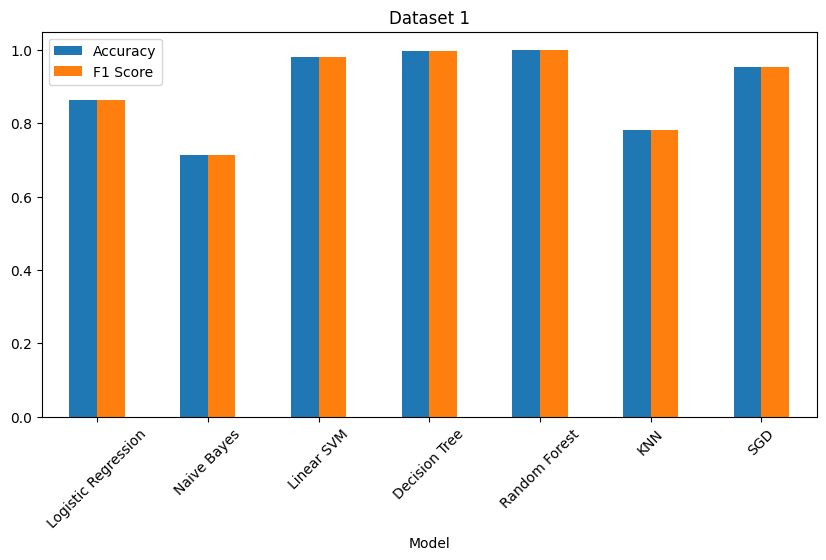

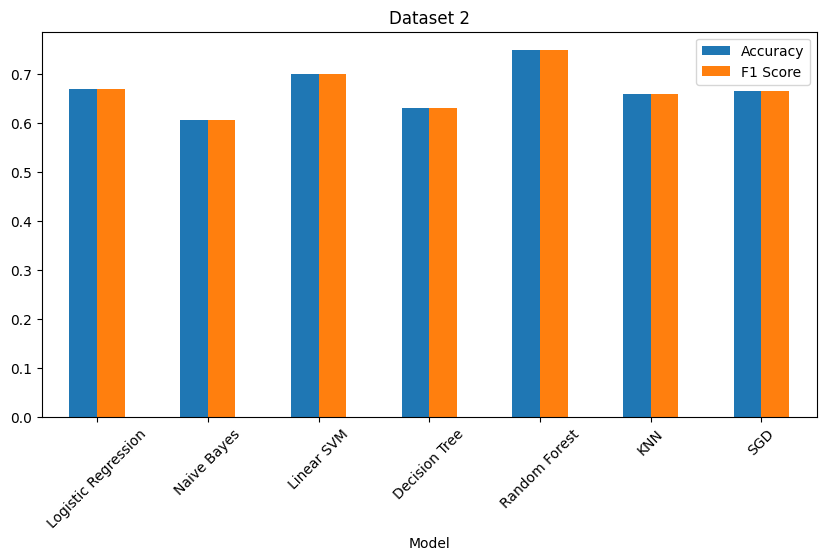

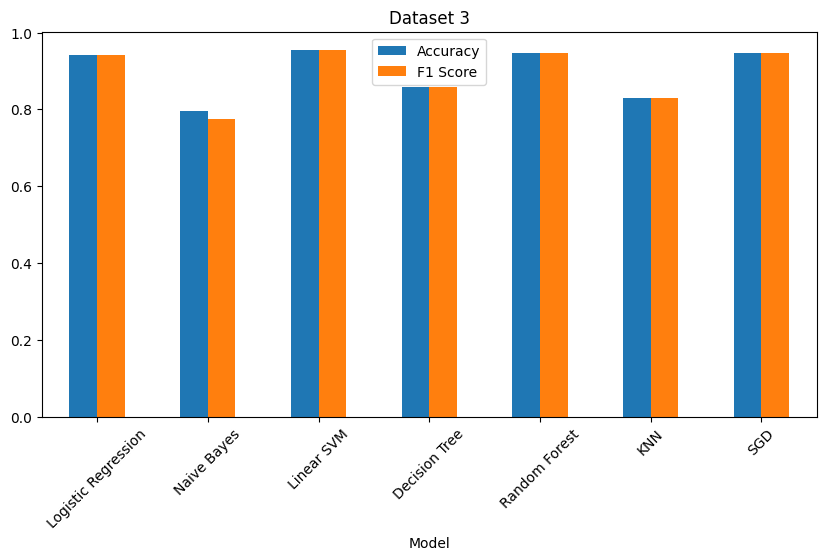

In [18]:
def plot_results(df, title):
    df.set_index("Model")[["Accuracy", "F1 Score"]].plot(kind='bar', figsize=(10,5))
    plt.title(title)
    plt.xticks(rotation=45)
    plt.show()

plot_results(res1, "Dataset 1")
plot_results(res2, "Dataset 2")
plot_results(res3, "Dataset 3")

#  Import TensorFlow / Keras Libraries

In [19]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.metrics import confusion_matrix
import seaborn as sns

# Tokenization & Padding

Convert text into sequences and pad them to fixed length.

In [20]:
MAX_WORDS = 10000
MAX_LEN = 200

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")

# Fit on ALL datasets combined (better vocabulary)
all_text = pd.concat([
    df1_final['clean_text'],
    df2_final['clean_text'],
    df3_final['clean_text']
])

tokenizer.fit_on_texts(all_text)


def prepare_dl_data(X_train, X_test):
    X_train_seq = tokenizer.texts_to_sequences(X_train)
    X_test_seq = tokenizer.texts_to_sequences(X_test)

    X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post')
    X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post')

    return X_train_pad, X_test_pad


X1_train_pad, X1_test_pad = prepare_dl_data(X1_train, X1_test)
X2_train_pad, X2_test_pad = prepare_dl_data(X2_train, X2_test)
X3_train_pad, X3_test_pad = prepare_dl_data(X3_train, X3_test)

#  LSTM Model Architecture

In [21]:
def build_lstm():
    model = Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        LSTM(128, return_sequences=False),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    return model

# GRU Model Architecture

In [22]:
def build_gru():
    model = Sequential([
        Embedding(MAX_WORDS, 128, input_length=MAX_LEN),
        GRU(128, return_sequences=False),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    return model

#  Training Function for Models

In [23]:
def train_dl_model(model, X_train, y_train, X_test, y_test, name):
    history = model.fit(
        X_train, y_train,
        epochs=5,
        batch_size=32,
        validation_data=(X_test, y_test),
        verbose=1
    )
    return history

#  Train LSTM on All 3 Datasets

In [24]:
lstm1 = build_lstm()
hist_lstm1 = train_dl_model(lstm1, X1_train_pad, y1_train, X1_test_pad, y1_test, "LSTM-DS1")

lstm2 = build_lstm()
hist_lstm2 = train_dl_model(lstm2, X2_train_pad, y2_train, X2_test_pad, y2_test, "LSTM-DS2")

lstm3 = build_lstm()
hist_lstm3 = train_dl_model(lstm3, X3_train_pad, y3_train, X3_test_pad, y3_test, "LSTM-DS3")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.7070 - loss: 0.5487 - val_accuracy: 0.9209 - val_loss: 0.2219
Epoch 2/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9726 - loss: 0.0799 - val_accuracy: 0.9926 - val_loss: 0.0178
Epoch 3/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9918 - loss: 0.0235 - val_accuracy: 0.9638 - val_loss: 0.1166
Epoch 4/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9934 - loss: 0.0189 - val_accuracy: 0.9951 - val_loss: 0.0075
Epoch 5/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9961 - loss: 0.0075 - val_accuracy: 0.9951 - val_loss: 0.0069
Epoch 1/5
579/579 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.6596 - loss: 0.6144 - val_accuracy: 0.7245 - val_loss: 0.5568
Epoch 2/5
579/579 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8289 - loss: 0.3943 - val_accuracy: 0.8029 - val_loss: 0.4381
Epoch 3/5
579/579 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9157 - loss: 0.2163 - val_accuracy: 0

#  Train GRU on All 3 Datasets

In [25]:
gru1 = build_gru()
hist_gru1 = train_dl_model(gru1, X1_train_pad, y1_train, X1_test_pad, y1_test, "GRU-DS1")

gru2 = build_gru()
hist_gru2 = train_dl_model(gru2, X2_train_pad, y2_train, X2_test_pad, y2_test, "GRU-DS2")

gru3 = build_gru()
hist_gru3 = train_dl_model(gru3, X3_train_pad, y3_train, X3_test_pad, y3_test, "GRU-DS3")

Epoch 1/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.7342 - loss: 0.4998 - val_accuracy: 0.9234 - val_loss: 0.1848
Epoch 2/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9761 - loss: 0.0747 - val_accuracy: 0.9918 - val_loss: 0.0197
Epoch 3/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9946 - loss: 0.0124 - val_accuracy: 0.9959 - val_loss: 0.0095
Epoch 4/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9951 - loss: 0.0126 - val_accuracy: 0.9885 - val_loss: 0.0566
Epoch 5/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9940 - loss: 0.0158 - val_accuracy: 0.9951 - val_loss: 0.0087
Epoch 1/5
579/579 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.6479 - loss: 0.6240 - val_accuracy: 0.7053 - val_loss: 0.5761
Epoch 2/5
579/579 ━━━━━━━━━━━━━━━━━━━━ 18s 32ms/step - accuracy: 0.8116 - loss: 0.4247 - val_accuracy: 0.7900 - val_loss: 0.4486
Epoch 3/5
579/579 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9071 - loss: 0.2344 - val_accuracy: 

#  Training Curves (Accuracy & Loss)

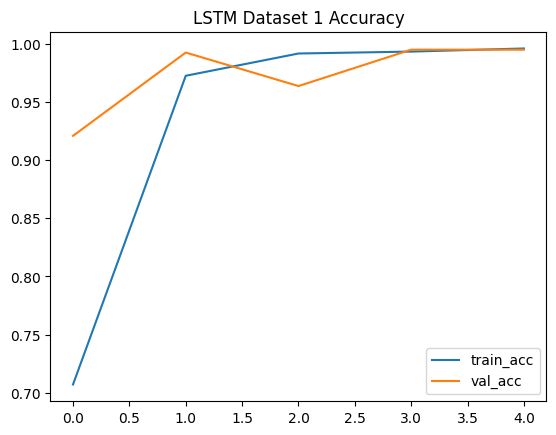

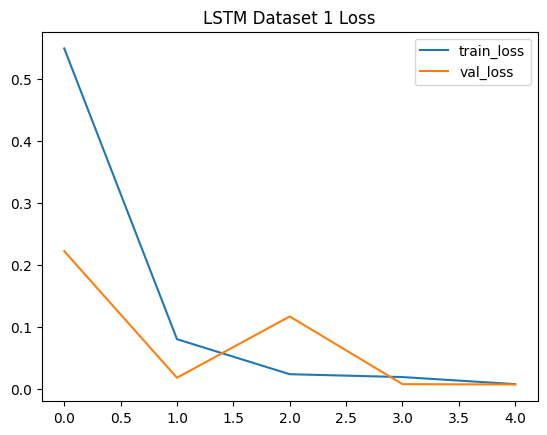

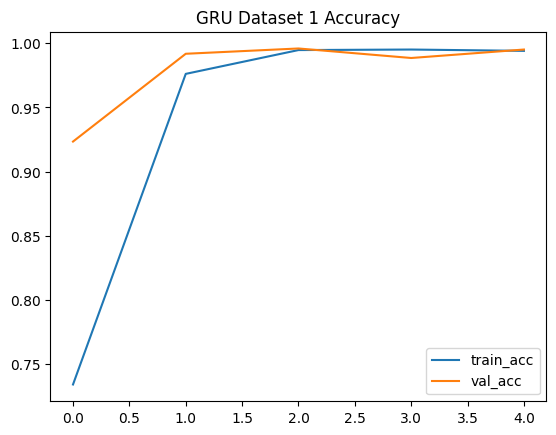

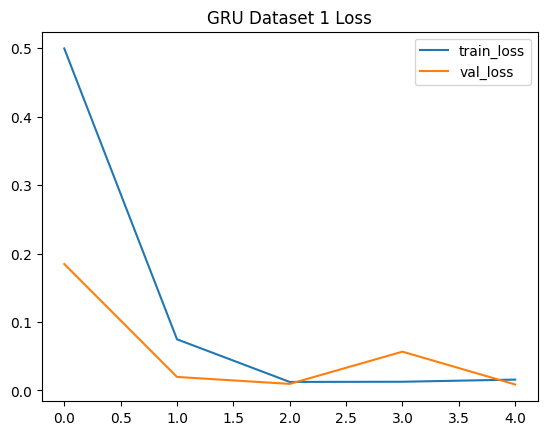

In [26]:
def plot_history(history, title):
    plt.figure()
    plt.plot(history.history['accuracy'], label='train_acc')
    plt.plot(history.history['val_accuracy'], label='val_acc')
    plt.title(title + " Accuracy")
    plt.legend()
    plt.show()

    plt.figure()
    plt.plot(history.history['loss'], label='train_loss')
    plt.plot(history.history['val_loss'], label='val_loss')
    plt.title(title + " Loss")
    plt.legend()
    plt.show()


plot_history(hist_lstm1, "LSTM Dataset 1")
plot_history(hist_gru1, "GRU Dataset 1")

#  Model Evaluation (Accuracy, F1, Confusion Matrix)

In [27]:
def evaluate_model(model, X_test, y_test, name):
    preds = (model.predict(X_test) > 0.5).astype(int)

    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    print(f"\n{name} Results")
    print("Accuracy:", acc)
    print("F1 Score:", f1)

    print("\nClassification Report:")
    print(classification_report(y_test, preds))

    cm = confusion_matrix(y_test, preds)
    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(name + " Confusion Matrix")
    plt.show()

    return acc, f1

#  Evaluate LSTM & GRU on All Datasets

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step

LSTM DS1 Results
Accuracy: 0.9950576606260296
F1 Score: 0.9953051643192489

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       572
           1       1.00      0.99      1.00       642

    accuracy                           1.00      1214
   macro avg       0.99      1.00      1.00      1214
weighted avg       1.00      1.00      1.00      1214



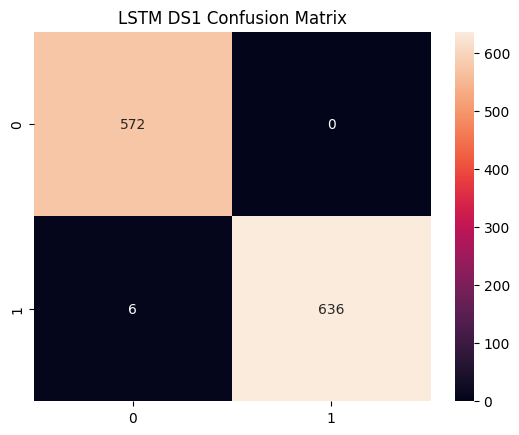

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step

GRU DS1 Results
Accuracy: 0.9950576606260296
F1 Score: 0.9953051643192489

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       572
           1       1.00      0.99      1.00       642

    accuracy                           1.00      1214
   macro avg       0.99      1.00      1.00      1214
weighted avg       1.00      1.00      1.00      1214



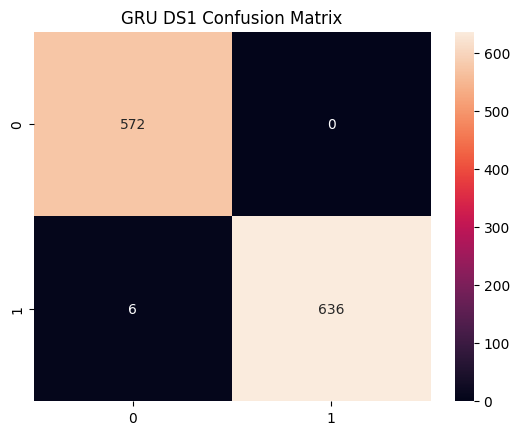

145/145 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step

LSTM DS2 Results
Accuracy: 0.8915298184961107
F1 Score: 0.900633412509897

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.86      0.88      2140
           1       0.89      0.91      0.90      2488

    accuracy                           0.89      4628
   macro avg       0.89      0.89      0.89      4628
weighted avg       0.89      0.89      0.89      4628



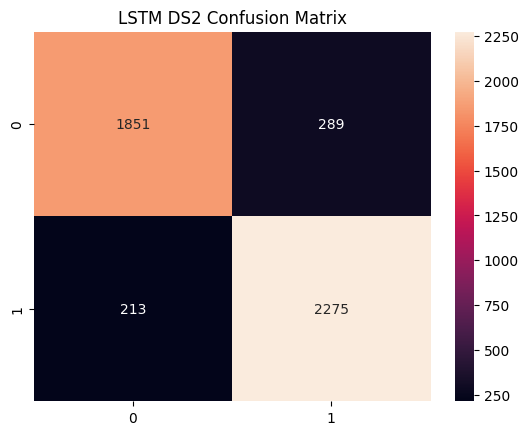

145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step

GRU DS2 Results
Accuracy: 0.8952031114952463
F1 Score: 0.9029029029029029

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.89      2140
           1       0.90      0.91      0.90      2488

    accuracy                           0.90      4628
   macro avg       0.89      0.89      0.89      4628
weighted avg       0.90      0.90      0.90      4628



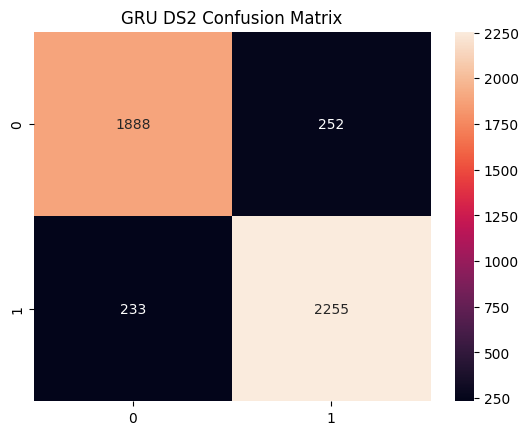

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step

LSTM DS3 Results
Accuracy: 0.6333333333333333
F1 Score: 0.7755102040816326

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        88
           1       0.63      1.00      0.78       152

    accuracy                           0.63       240
   macro avg       0.32      0.50      0.39       240
weighted avg       0.40      0.63      0.49       240



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


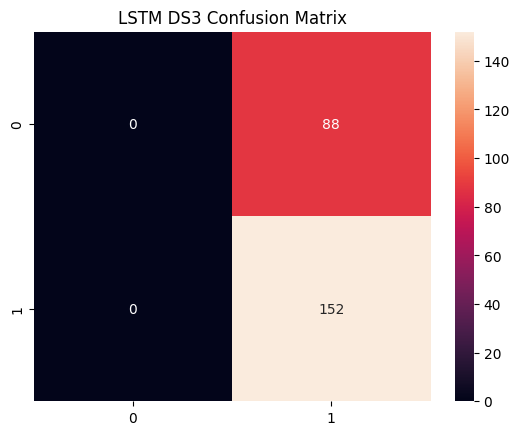

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step

GRU DS3 Results
Accuracy: 0.6333333333333333
F1 Score: 0.7755102040816326

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        88
           1       0.63      1.00      0.78       152

    accuracy                           0.63       240
   macro avg       0.32      0.50      0.39       240
weighted avg       0.40      0.63      0.49       240



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


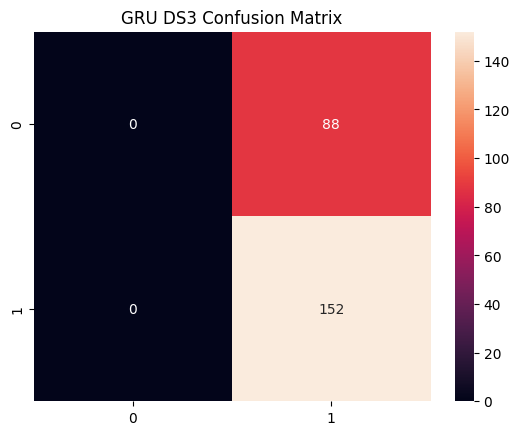

  Model Dataset  Accuracy        F1
0  LSTM     DS1  0.995058  0.995305
1   GRU     DS1  0.995058  0.995305
2  LSTM     DS2  0.891530  0.900633
3   GRU     DS2  0.895203  0.902903
4  LSTM     DS3  0.633333  0.775510
5   GRU     DS3  0.633333  0.775510


In [28]:
results_dl = []

# Dataset 1
acc, f1 = evaluate_model(lstm1, X1_test_pad, y1_test, "LSTM DS1")
results_dl.append(["LSTM", "DS1", acc, f1])

acc, f1 = evaluate_model(gru1, X1_test_pad, y1_test, "GRU DS1")
results_dl.append(["GRU", "DS1", acc, f1])


# Dataset 2
acc, f1 = evaluate_model(lstm2, X2_test_pad, y2_test, "LSTM DS2")
results_dl.append(["LSTM", "DS2", acc, f1])

acc, f1 = evaluate_model(gru2, X2_test_pad, y2_test, "GRU DS2")
results_dl.append(["GRU", "DS2", acc, f1])


# Dataset 3
acc, f1 = evaluate_model(lstm3, X3_test_pad, y3_test, "LSTM DS3")
results_dl.append(["LSTM", "DS3", acc, f1])

acc, f1 = evaluate_model(gru3, X3_test_pad, y3_test, "GRU DS3")
results_dl.append(["GRU", "DS3", acc, f1])


results_dl_df = pd.DataFrame(results_dl, columns=["Model", "Dataset", "Accuracy", "F1"])
print(results_dl_df)

#  Compare LSTM vs GRU Across Datasets

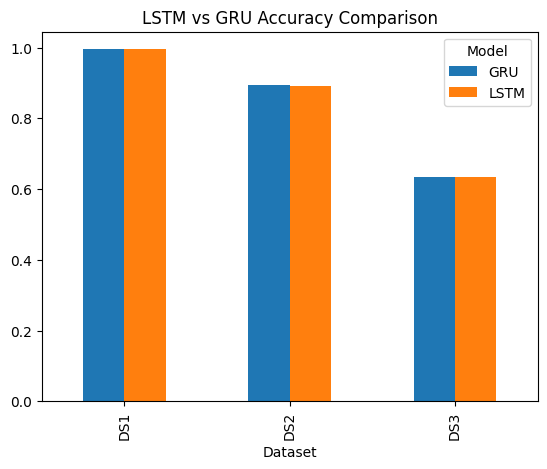

In [29]:
pivot = results_dl_df.pivot(index="Dataset", columns="Model", values="Accuracy")

pivot.plot(kind='bar')
plt.title("LSTM vs GRU Accuracy Comparison")
plt.show()

#  Install Gensim for Word2Vec

In [30]:
!pip install -q gensim

#  Prepare Corpus for Word Embeddings

We combine all datasets for better vocabulary learning.

In [31]:
corpus = pd.concat([
    df1_final['clean_text'],
    df2_final['clean_text'],
    df3_final['clean_text']
])

corpus_tokens = [text.split() for text in corpus]

# Train Word2Vec Model

In [32]:
from gensim.models import Word2Vec

w2v_model = Word2Vec(
    sentences=corpus_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4
)

print("Word2Vec Vocabulary Size:", len(w2v_model.wv))

Word2Vec Vocabulary Size: 119554


#  Create Embedding Matrix (Word2Vec)

In [33]:
embedding_dim = 100
word_index = tokenizer.word_index

embedding_matrix_w2v = np.zeros((MAX_WORDS, embedding_dim))

for word, i in word_index.items():
    if i < MAX_WORDS and word in w2v_model.wv:
        embedding_matrix_w2v[i] = w2v_model.wv[word]

#  Load GloVe Embeddings

Using pretrained GloVe vectors.

In [34]:
!wget http://nlp.stanford.edu/data/glove.6B.zip
!unzip glove.6B.zip

--2026-03-31 15:40:59--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2026-03-31 15:41:00--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2026-03-31 15:41:00--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

#  Create GloVe Embedding Matrix

In [35]:
embeddings_index = {}

with open("glove.6B.100d.txt", encoding='utf8') as f:
    for line in f:
        values = line.split()
        word = values[0]
        coefs = np.asarray(values[1:], dtype='float32')
        embeddings_index[word] = coefs

embedding_matrix_glove = np.zeros((MAX_WORDS, 100))

for word, i in word_index.items():
    if i < MAX_WORDS and word in embeddings_index:
        embedding_matrix_glove[i] = embeddings_index[word]

#  LSTM with Pretrained Embeddings

In [36]:
def build_lstm_embedding(embedding_matrix):
    model = Sequential([
        Embedding(
            input_dim=MAX_WORDS,
            output_dim=100,
            weights=[embedding_matrix],
            input_length=MAX_LEN,
            trainable=False
        ),
        LSTM(128),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

# GRU with Pretrained Embeddings

In [37]:
def build_gru_embedding(embedding_matrix):
    model = Sequential([
        Embedding(
            input_dim=MAX_WORDS,
            output_dim=100,
            weights=[embedding_matrix],
            input_length=MAX_LEN,
            trainable=False
        ),
        GRU(128),
        Dropout(0.3),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

# Train Models using Word2Vec Embeddings

In [38]:
lstm_w2v = build_lstm_embedding(embedding_matrix_w2v)
hist_lstm_w2v = lstm_w2v.fit(X1_train_pad, y1_train, epochs=5, validation_data=(X1_test_pad, y1_test))

gru_w2v = build_gru_embedding(embedding_matrix_w2v)
hist_gru_w2v = gru_w2v.fit(X1_train_pad, y1_train, epochs=5, validation_data=(X1_test_pad, y1_test))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.6506 - loss: 0.6241 - val_accuracy: 0.7562 - val_loss: 0.5254
Epoch 2/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.8611 - loss: 0.3533 - val_accuracy: 0.9423 - val_loss: 0.2106
Epoch 3/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.9619 - loss: 0.1224 - val_accuracy: 0.9918 - val_loss: 0.0477
Epoch 4/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9916 - loss: 0.0358 - val_accuracy: 0.9951 - val_loss: 0.0260
Epoch 5/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9905 - loss: 0.0337 - val_accuracy: 0.9885 - val_loss: 0.0323
Epoch 1/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 12s 44ms/step - accuracy: 0.6368 - loss: 0.6360 - val_accuracy: 0.7488 - val_loss: 0.5443
Epoch 2/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - accuracy: 0.8166 - loss: 0.4364 - val_accuracy: 0.8995 - val_loss: 0.3311
Epoch 3/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.9265 - loss: 0.2078 - val_accuracy: 0

# Train Models using GloVe Embeddings

In [39]:
lstm_glove = build_lstm_embedding(embedding_matrix_glove)
hist_lstm_glove = lstm_glove.fit(X1_train_pad, y1_train, epochs=5, validation_data=(X1_test_pad, y1_test))

gru_glove = build_gru_embedding(embedding_matrix_glove)
hist_gru_glove = gru_glove.fit(X1_train_pad, y1_train, epochs=5, validation_data=(X1_test_pad, y1_test))

Epoch 1/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.5707 - loss: 0.6764 - val_accuracy: 0.6384 - val_loss: 0.6386
Epoch 2/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.6564 - loss: 0.6224 - val_accuracy: 0.7092 - val_loss: 0.5727
Epoch 3/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.7691 - loss: 0.4981 - val_accuracy: 0.7924 - val_loss: 0.4610
Epoch 4/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 15s 72ms/step - accuracy: 0.8766 - loss: 0.3125 - val_accuracy: 0.9110 - val_loss: 0.2450
Epoch 5/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.9582 - loss: 0.1349 - val_accuracy: 0.9465 - val_loss: 0.1448
Epoch 1/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.5760 - loss: 0.6717 - val_accuracy: 0.6071 - val_loss: 0.6465
Epoch 2/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.6733 - loss: 0.6089 - val_accuracy: 0.7076 - val_loss: 0.5805
Epoch 3/5
152/152 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7548 - loss: 0.5144 - val_accuracy: 

#  Evaluate Embedding Models

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

LSTM + W2V Results
Accuracy: 0.9884678747940692
F1 Score: 0.9892141756548536

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       572
           1       0.98      1.00      0.99       642

    accuracy                           0.99      1214
   macro avg       0.99      0.99      0.99      1214
weighted avg       0.99      0.99      0.99      1214



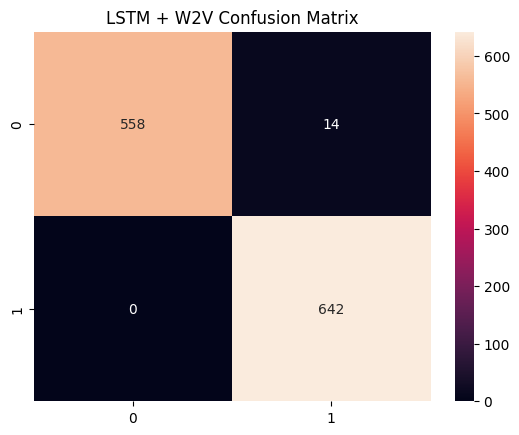

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

GRU + W2V Results
Accuracy: 0.999176276771005
F1 Score: 0.9992205767731879

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       572
           1       1.00      1.00      1.00       642

    accuracy                           1.00      1214
   macro avg       1.00      1.00      1.00      1214
weighted avg       1.00      1.00      1.00      1214



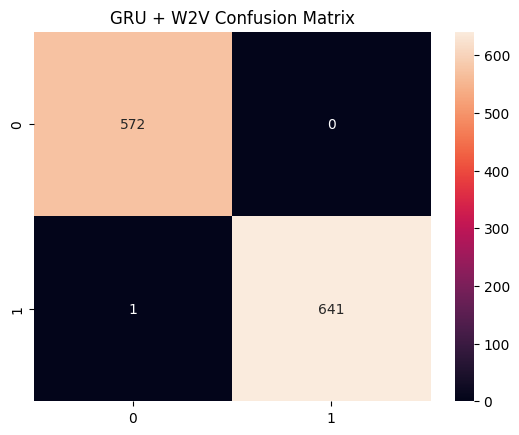

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step

LSTM + GloVe Results
Accuracy: 0.9464579901153213
F1 Score: 0.9483717235901509

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.94       572
           1       0.97      0.93      0.95       642

    accuracy                           0.95      1214
   macro avg       0.95      0.95      0.95      1214
weighted avg       0.95      0.95      0.95      1214



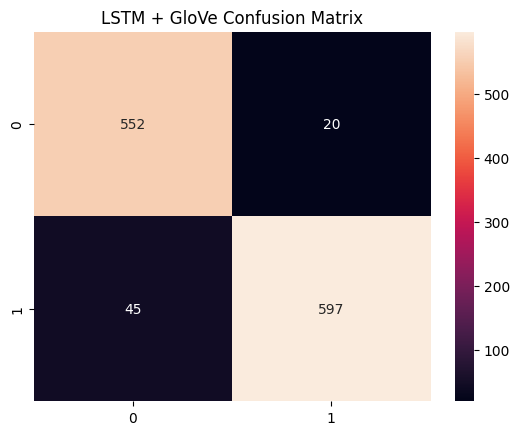

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step

GRU + GloVe Results
Accuracy: 0.9695222405271828
F1 Score: 0.9711163153786104

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       572
           1       0.97      0.97      0.97       642

    accuracy                           0.97      1214
   macro avg       0.97      0.97      0.97      1214
weighted avg       0.97      0.97      0.97      1214



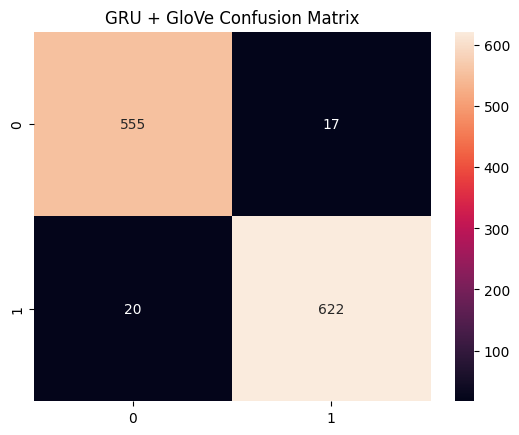

(0.9695222405271828, 0.9711163153786104)

In [40]:
evaluate_model(lstm_w2v, X1_test_pad, y1_test, "LSTM + W2V")
evaluate_model(gru_w2v, X1_test_pad, y1_test, "GRU + W2V")

evaluate_model(lstm_glove, X1_test_pad, y1_test, "LSTM + GloVe")
evaluate_model(gru_glove, X1_test_pad, y1_test, "GRU + GloVe")

#  Embedding Model Comparison

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

LSTM W2V Results
Accuracy: 0.9884678747940692
F1 Score: 0.9892141756548536

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       572
           1       0.98      1.00      0.99       642

    accuracy                           0.99      1214
   macro avg       0.99      0.99      0.99      1214
weighted avg       0.99      0.99      0.99      1214



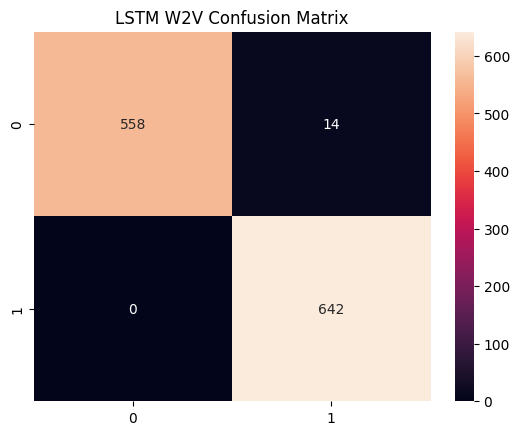

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

GRU W2V Results
Accuracy: 0.999176276771005
F1 Score: 0.9992205767731879

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       572
           1       1.00      1.00      1.00       642

    accuracy                           1.00      1214
   macro avg       1.00      1.00      1.00      1214
weighted avg       1.00      1.00      1.00      1214



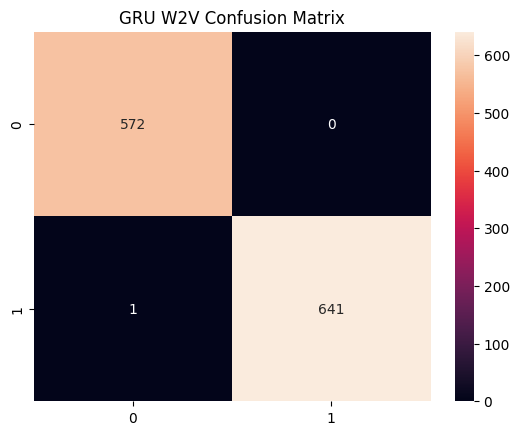

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

LSTM GloVe Results
Accuracy: 0.9464579901153213
F1 Score: 0.9483717235901509

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.94       572
           1       0.97      0.93      0.95       642

    accuracy                           0.95      1214
   macro avg       0.95      0.95      0.95      1214
weighted avg       0.95      0.95      0.95      1214



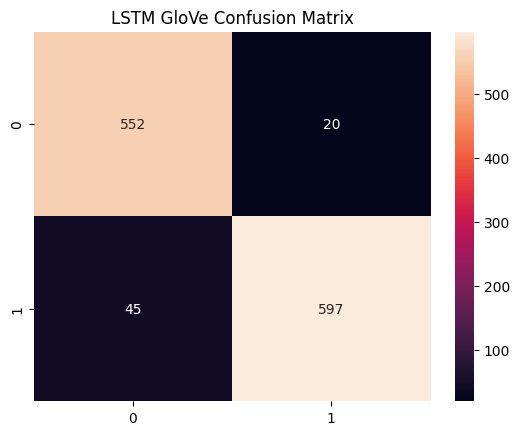

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

GRU GloVe Results
Accuracy: 0.9695222405271828
F1 Score: 0.9711163153786104

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       572
           1       0.97      0.97      0.97       642

    accuracy                           0.97      1214
   macro avg       0.97      0.97      0.97      1214
weighted avg       0.97      0.97      0.97      1214



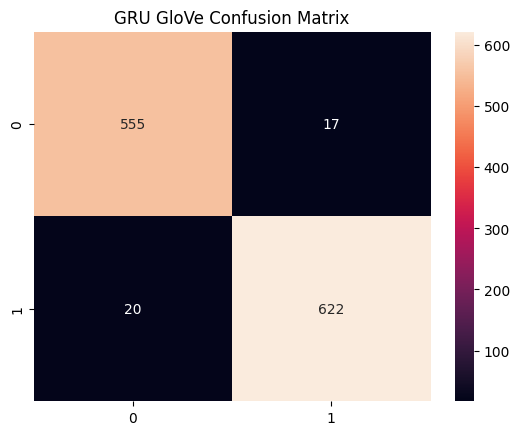

,Model,Accuracy,F1
0,LSTM + W2V,0.988468,0.989214
1,GRU + W2V,0.999176,0.999221
2,LSTM + GloVe,0.946458,0.948372
3,GRU + GloVe,0.969522,0.971116


In [41]:
results_embed = [
    ["LSTM + W2V", *evaluate_model(lstm_w2v, X1_test_pad, y1_test, "LSTM W2V")],
    ["GRU + W2V", *evaluate_model(gru_w2v, X1_test_pad, y1_test, "GRU W2V")],
    ["LSTM + GloVe", *evaluate_model(lstm_glove, X1_test_pad, y1_test, "LSTM GloVe")],
    ["GRU + GloVe", *evaluate_model(gru_glove, X1_test_pad, y1_test, "GRU GloVe")]
]

pd.DataFrame(results_embed, columns=["Model", "Accuracy", "F1"])

# 🔧 Install Hugging Face Transformers

In [42]:
!pip install -q transformers datasets evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.6 MB/s eta 0:00:00


#  Import Required Libraries

In [65]:
import torch
from datasets import Dataset
from transformers import DataCollatorWithPadding

from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments
)

import evaluate

#  Convert Pandas DataFrames to HuggingFace Dataset Format

In [44]:
def to_hf_dataset(df):
    return Dataset.from_pandas(df[['clean_text', 'label']])

hf_ds1 = to_hf_dataset(df1_final)
hf_ds2 = to_hf_dataset(df2_final)
hf_ds3 = to_hf_dataset(df3_final)

# Train-Test Split

In [45]:
hf_ds1 = hf_ds1.train_test_split(test_size=0.2)
hf_ds2 = hf_ds2.train_test_split(test_size=0.2)
hf_ds3 = hf_ds3.train_test_split(test_size=0.2)

#  Load BERT Tokenizer

In [46]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

#  Tokenization Function

In [47]:
def tokenize(example):
    return tokenizer(
        example['clean_text'],
        padding='max_length',
        truncation=True,
        max_length=256
    )

#  Apply Tokenization to All Datasets

In [48]:
hf_ds1 = hf_ds1.map(tokenize, batched=True)
hf_ds2 = hf_ds2.map(tokenize, batched=True)
hf_ds3 = hf_ds3.map(tokenize, batched=True)

hf_ds1.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
hf_ds2.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
hf_ds3.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

Map:   0%|          | 0/4854 [00:00<?, ? examples/s]

Map:   0%|          | 0/1214 [00:00<?, ? examples/s]

Map:   0%|          | 0/18511 [00:00<?, ? examples/s]

Map:   0%|          | 0/4628 [00:00<?, ? examples/s]

Map:   0%|          | 0/960 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

#  Load BERT Model

In [49]:
def load_model():
    return BertForSequenceClassification.from_pretrained(
        'bert-base-uncased',
        num_labels=2
    )

#  Evaluation Metrics (Accuracy, Precision, Recall, F1)

In [50]:
accuracy = evaluate.load("accuracy")
precision = evaluate.load("precision")
recall = evaluate.load("recall")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=1)

    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "precision": precision.compute(predictions=preds, references=labels)["precision"],
        "recall": recall.compute(predictions=preds, references=labels)["recall"],
        "f1": f1.compute(predictions=preds, references=labels)["f1"],
    }

#  Training Function for BERT

In [66]:
def train_bert(hf_dataset, name):
    model = load_model()

    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    training_args = TrainingArguments(
        output_dir=f"./results_{name}",
        learning_rate=2e-5,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        num_train_epochs=2,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=hf_dataset['train'],
        eval_dataset=hf_dataset['test'],
        data_collator=data_collator,
        compute_metrics=compute_metrics
    )

    trainer.train()
    metrics = trainer.evaluate()

    return trainer, metrics

#  Fine-Tune BERT on Dataset 1

In [67]:
trainer1, metrics1 = train_bert(hf_ds1, "ds1")
print(metrics1)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.668036,0.504490,0.764415,0.723011,0.848333,0.780675
2,0.393792,0.263951,0.922570,0.925926,0.916667,0.921273


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

{'eval_loss': 0.26395145058631897, 'eval_accuracy': 0.9225700164744646, 'eval_precision': 0.9259259259259259, 'eval_recall': 0.9166666666666666, 'eval_f1': 0.9212730318257957, 'eval_runtime': 16.9009, 'eval_samples_per_second': 71.83, 'eval_steps_per_second': 8.994, 'epoch': 2.0}


#  Fine-Tune BERT on Dataset 2

In [68]:
trainer2, metrics2 = train_bert(hf_ds2, "ds2")
print(metrics2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.673913,0.669483,0.584486,0.621756,0.516798,0.564439
2,0.648003,0.673019,0.598963,0.622517,0.584820,0.603080


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

{'eval_loss': 0.6694060564041138, 'eval_accuracy': 0.5847018150388937, 'eval_precision': 0.6218236173393124, 'eval_recall': 0.5176275404396516, 'eval_f1': 0.564961521050249, 'eval_runtime': 66.7619, 'eval_samples_per_second': 69.321, 'eval_steps_per_second': 8.673, 'epoch': 2.0}


# Fine-Tune BERT on Dataset 3

In [69]:
trainer3, metrics3 = train_bert(hf_ds3, "ds3")
print(metrics3)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,No log,0.219417,0.912500,0.940397,0.922078,0.931148
2,No log,0.149585,0.954167,0.973510,0.954545,0.963934


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

{'eval_loss': 0.14958472549915314, 'eval_accuracy': 0.9541666666666667, 'eval_precision': 0.9735099337748344, 'eval_recall': 0.9545454545454546, 'eval_f1': 0.9639344262295082, 'eval_runtime': 3.3493, 'eval_samples_per_second': 71.656, 'eval_steps_per_second': 8.957, 'epoch': 2.0}


#  Confusion Matrix for BERT

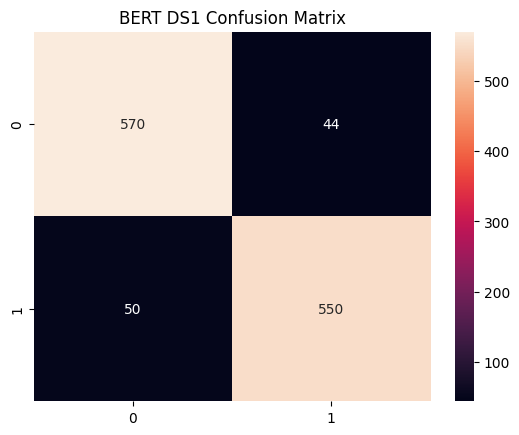

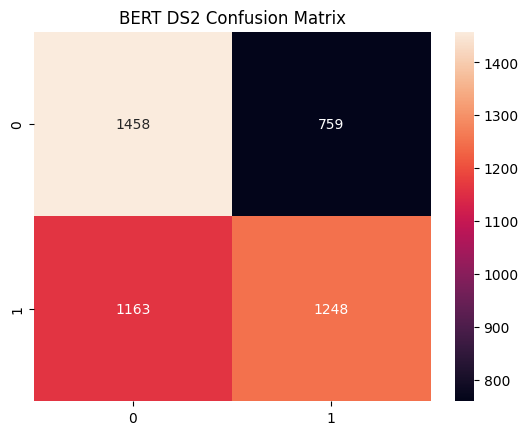

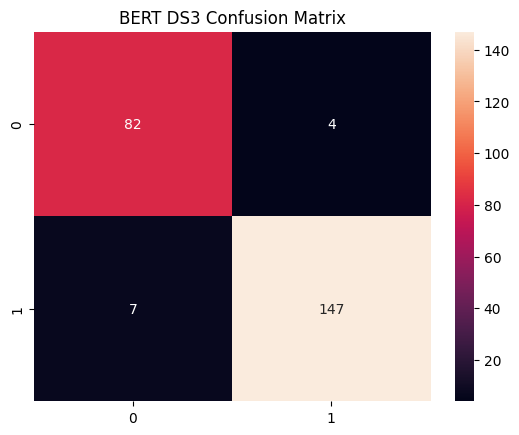

In [70]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def plot_confusion(trainer, dataset, name):
    preds = trainer.predict(dataset['test'])
    y_pred = preds.predictions.argmax(axis=1)
    y_true = preds.label_ids

    cm = confusion_matrix(y_true, y_pred)

    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(name + " Confusion Matrix")
    plt.show()

plot_confusion(trainer1, hf_ds1, "BERT DS1")
plot_confusion(trainer2, hf_ds2, "BERT DS2")
plot_confusion(trainer3, hf_ds3, "BERT DS3")

# 📋 BERT Results Comparison

In [71]:
bert_results = pd.DataFrame([
    ["Dataset 1", metrics1['eval_accuracy'], metrics1['eval_f1']],
    ["Dataset 2", metrics2['eval_accuracy'], metrics2['eval_f1']],
    ["Dataset 3", metrics3['eval_accuracy'], metrics3['eval_f1']]
], columns=["Dataset", "Accuracy", "F1 Score"])

print(bert_results)

     Dataset  Accuracy  F1 Score
0  Dataset 1  0.922570  0.921273
1  Dataset 2  0.584702  0.564962
2  Dataset 3  0.954167  0.963934


#  Load DistilBERT (Lightweight LLM)

In [72]:
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

distil_tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

#  Tokenization for DistilBERT

In [73]:
def tokenize_distil(example):
    return distil_tokenizer(
        example['clean_text'],
        padding='max_length',
        truncation=True,
        max_length=256
    )

#  Apply Tokenization to All Datasets

In [74]:
hf_ds1_d = hf_ds1.map(tokenize_distil, batched=True)
hf_ds2_d = hf_ds2.map(tokenize_distil, batched=True)
hf_ds3_d = hf_ds3.map(tokenize_distil, batched=True)

hf_ds1_d.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
hf_ds2_d.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
hf_ds3_d.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

Map:   0%|          | 0/4854 [00:00<?, ? examples/s]

Map:   0%|          | 0/1214 [00:00<?, ? examples/s]

Map:   0%|          | 0/18511 [00:00<?, ? examples/s]

Map:   0%|          | 0/4628 [00:00<?, ? examples/s]

Map:   0%|          | 0/960 [00:00<?, ? examples/s]

Map:   0%|          | 0/240 [00:00<?, ? examples/s]

#  Load DistilBERT Model

In [75]:
def load_distil_model():
    return DistilBertForSequenceClassification.from_pretrained(
        'distilbert-base-uncased',
        num_labels=2
    )

# Fast Training Configuration (Optimized for Speed + Accuracy)

Techniques used:
- Fewer epochs (2)
- Smaller batch size
- FP16 (if GPU)
- Early stopping

In [76]:
from transformers import EarlyStoppingCallback, DataCollatorWithPadding
import torch

def train_distil(hf_dataset, name):
    model = load_distil_model()

    # ✅ FIX: Use DataCollator instead of tokenizer
    data_collator = DataCollatorWithPadding(tokenizer=distil_tokenizer)

    # ✅ FIX: fp16 only if GPU available
    use_fp16 = torch.cuda.is_available()

    training_args = TrainingArguments(
        output_dir=f"./distil_{name}",
        learning_rate=3e-5,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        num_train_epochs=2,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=100,
        fp16=use_fp16,
        load_best_model_at_end=True,
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=hf_dataset['train'],
        eval_dataset=hf_dataset['test'],
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
    )

    trainer.train()
    metrics = trainer.evaluate()

    return trainer, metrics

#  DistilBERT on Dataset 1

In [77]:
distil_trainer1, distil_metrics1 = train_distil(hf_ds1_d, "ds1")
print(distil_metrics1)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.652839,0.630567,0.646623,0.674134,0.551667,0.606783
2,0.395003,0.444415,0.808896,0.786604,0.841667,0.813205


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


{'eval_loss': 0.44441476464271545, 'eval_accuracy': 0.8088962108731467, 'eval_precision': 0.7866043613707165, 'eval_recall': 0.8416666666666667, 'eval_f1': 0.8132045088566827, 'eval_runtime': 2.5758, 'eval_samples_per_second': 471.301, 'eval_steps_per_second': 59.01, 'epoch': 2.0}


#  DistilBERT on Dataset 2

In [78]:
distil_trainer2, distil_metrics2 = train_distil(hf_ds2_d, "ds2")
print(distil_metrics2)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.671614,0.668379,0.582325,0.601100,0.589382,0.595183
2,0.665010,0.675668,0.596586,0.625461,0.562422,0.592269


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


{'eval_loss': 0.6683675646781921, 'eval_accuracy': 0.5825410544511668, 'eval_precision': 0.6012684989429176, 'eval_recall': 0.5897967648278722, 'eval_f1': 0.5954773869346733, 'eval_runtime': 9.912, 'eval_samples_per_second': 466.908, 'eval_steps_per_second': 58.414, 'epoch': 2.0}


#  DistilBERT on Dataset 3

In [79]:
distil_trainer3, distil_metrics3 = train_distil(hf_ds3_d, "ds3")
print(distil_metrics3)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.557855,0.168285,0.954167,0.949686,0.980519,0.964856
2,0.177097,0.171559,0.937500,0.972789,0.928571,0.950166


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


{'eval_loss': 0.16819247603416443, 'eval_accuracy': 0.9541666666666667, 'eval_precision': 0.949685534591195, 'eval_recall': 0.9805194805194806, 'eval_f1': 0.9648562300319489, 'eval_runtime': 0.6427, 'eval_samples_per_second': 373.404, 'eval_steps_per_second': 46.676, 'epoch': 2.0}


# Confusion Matrix for DistilBERT

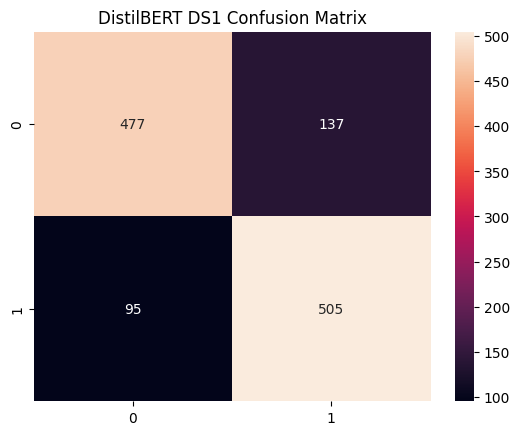

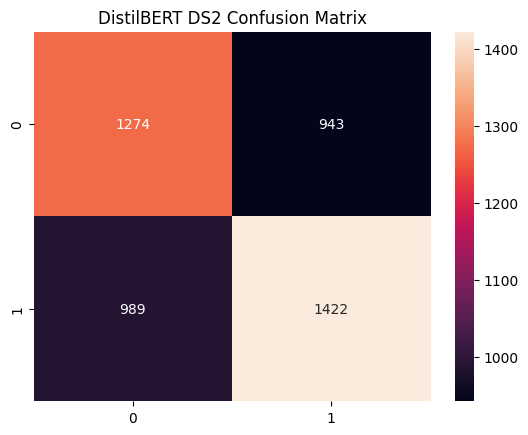

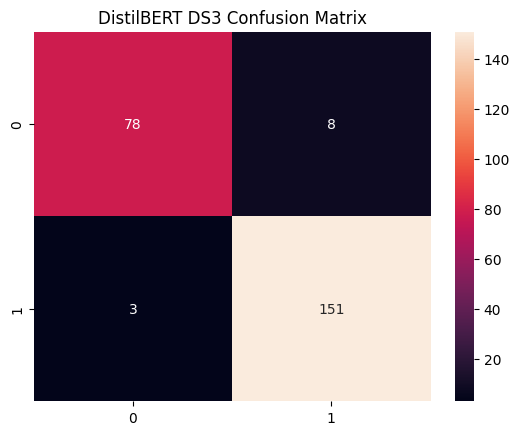

In [80]:
plot_confusion(distil_trainer1, hf_ds1_d, "DistilBERT DS1")
plot_confusion(distil_trainer2, hf_ds2_d, "DistilBERT DS2")
plot_confusion(distil_trainer3, hf_ds3_d, "DistilBERT DS3")

# Final Model Comparison

Includes:
- ML models
- LSTM/GRU
- BERT
- DistilBERT

In [81]:
final_results = pd.DataFrame([
    ["BERT DS1", metrics1['eval_accuracy'], metrics1['eval_f1']],
    ["DistilBERT DS1", distil_metrics1['eval_accuracy'], distil_metrics1['eval_f1']],

    ["BERT DS2", metrics2['eval_accuracy'], metrics2['eval_f1']],
    ["DistilBERT DS2", distil_metrics2['eval_accuracy'], distil_metrics2['eval_f1']],

    ["BERT DS3", metrics3['eval_accuracy'], metrics3['eval_f1']],
    ["DistilBERT DS3", distil_metrics3['eval_accuracy'], distil_metrics3['eval_f1']],
], columns=["Model", "Accuracy", "F1 Score"])

print(final_results)

            Model  Accuracy  F1 Score
0        BERT DS1  0.922570  0.921273
1  DistilBERT DS1  0.808896  0.813205
2        BERT DS2  0.584702  0.564962
3  DistilBERT DS2  0.582541  0.595477
4        BERT DS3  0.954167  0.963934
5  DistilBERT DS3  0.954167  0.964856


# 🔍 Real Case Prediction Demo

In [86]:
import torch

def predict_case(text, trainer):

    device = trainer.model.device


    inputs = distil_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    )


    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = trainer.model(**inputs)


    pred = torch.argmax(outputs.logits, dim=1).item()

    return "Favorable" if pred == 1 else "Not Favorable"



test_cases = [
    "The accused has no prior record and evidence is weak.",
    "Insufficient proof and procedural errors in investigation.",

]

print("\n🔎 Batch Predictions:\n")
for i, case in enumerate(test_cases):
    result = predict_case(case, distil_trainer3)
    print(f"Case {i+1}: {result}")


🔎 Batch Predictions:

Case 1: Favorable
Case 2: Favorable
